# FluxoBotanic — Projeto da Aula 13
### Previsão de movimento de clientes no ROYAL BOTANIC

**Disciplina:** Inteligência Artificial e LFA — UDF  
**Aluno:** João Matheus Bezerra  
**RGM:** 38964694

A ideia do trabalho é saber se um dia terá **alto** ou **baixo** movimento no stand. Para mim, um dia com **4 visitas ou mais é alto fluxo**. Com 0 a 3 visitas, o fluxo é baixo.

Usei dados reais de atendimentos, mas retirei os nomes. Este é um projeto para a faculdade, não um sistema pronto para fazer mudanças na empresa.


## 1. Perguntas da aula

**O que é aprendizado de máquina?** É quando um programa aprende padrões olhando exemplos e depois tenta prever novos casos.

**O que é aprendizado supervisionado?** É quando o programa aprende usando informações de entrada e respostas que já são conhecidas.

**O que são X e y?** X são os dados que usamos para tentar prever. y é a resposta certa dos exemplos. Aqui, y é `alto` ou `baixo`.

**Qual a diferença entre classificação e regressão?** Classificação diz uma categoria, como alto ou baixo. Regressão tenta prever um número, como a quantidade de visitas.

**Por que dividir em treino e teste?** Para ensinar o programa com uma parte dos dados e depois ver se ele acerta em datas que não usou para aprender.


## 2. Minha ideia para o projeto

Quero ajudar o pessoal da recepção e a coordenação a organizar os atendimentos.

- **O que vou prever:** fluxo alto ou baixo em cada dia.
- **O que o modelo recebe:** dia da semana, mês e histórico dos dias anteriores.
- **Rótulo y:** `alto` quando o dia teve 4 ou mais visitas; `baixo` quando teve até 3.
- **Outra informação:** se tem alguém disponível para reforçar a equipe.
- **O que o sistema devolve:** uma previsão e uma sugestão de organização.

O relatório não mostra quantos clientes já estavam agendados antes de o dia começar. Por isso, não usei a quantidade realizada do próprio dia para fazer a previsão.


## 3. Arquivo de visitas

Usei o arquivo `visitas_anonimizadas_royal_botanic.csv`. Ele tem apenas a data e o tipo de visita. **Não é necessário enviar ao Colab o PDF que tem nomes de clientes.**

O histórico tem **252 visitas**, sendo **193 agendadas e 59 espontâneas**, de 01/06 a 14/11/2026.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, ConfusionMatrixDisplay)

ARQUIVO = Path('visitas_anonimizadas_royal_botanic.csv')
if not ARQUIVO.exists():
    try:
        from google.colab import files
        print('Selecione visitas_anonimizadas_royal_botanic.csv')
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('Coloque o CSV na pasta do notebook ou execute no Google Colab.') from exc
print('Bibliotecas importadas e arquivo disponível:', ARQUIVO.exists())

Bibliotecas importadas e arquivo disponível: True


## 4. Parte principal do código

Aqui estão as funções que organizam os dados, treinam a Árvore de Decisão e procuram a regra correta para cada consulta. Separei as regras da parte que faz a busca.


In [2]:
LIMITE_ALTO = 4
ATRIBUTOS = ["dia_semana", "eh_sabado", "mes", "visitas_dia_anterior", 
            "media_visitas_ultimos_7_dias", "agendadas_ultimos_7_dias"]


def carregar_visitas(caminho):
    """Carrega registros sem nomes: somente data e tipo de atendimento."""
    dados = pd.read_csv(caminho)
    if set(dados.columns) != {"data", "tipo"}:
        raise ValueError("O CSV deve conter exatamente as colunas: data, tipo")
    if not set(dados["tipo"]).issubset({"agendada", "espontanea"}):
        raise ValueError("Tipo inválido no CSV.")
    dados["data"] = pd.to_datetime(dados["data"], errors="raise")
    if dados.empty:
        raise ValueError("O CSV está vazio.")
    return dados.sort_values("data").reset_index(drop=True)


def montar_dataset(visitas):
    """Uma linha por data do calendário. Dias sem registro são preenchidos com zero HIPOTÉTICO."""
    pivot = visitas.groupby(["data", "tipo"]).size().unstack(fill_value=0)
    pivot = pivot.rename(columns={"agendada":"agendadas_realizadas", 
                                  "espontanea":"espontaneas_realizadas"})
    for coluna in ("agendadas_realizadas", "espontaneas_realizadas"):
        if coluna not in pivot.columns:
            pivot[coluna] = 0
    periodo = pd.date_range(visitas["data"].min(), visitas["data"].max(), freq="D")
    diario = pivot.reindex(periodo, fill_value=0)
    diario.index.name = "data"
    diario = diario.reset_index()
    diario["sem_registro_no_pdf"] = (~diario["data"].isin(visitas["data"])).astype(int)
    diario["total_visitas"] = diario["agendadas_realizadas"] + diario["espontaneas_realizadas"]
    diario["fluxo"] = np.where(diario["total_visitas"] >= LIMITE_ALTO, "alto", "baixo")
    # Todos estes atributos são conhecidos no início do dia a prever.
    diario["dia_semana"] = diario["data"].dt.dayofweek
    diario["eh_sabado"] = (diario["dia_semana"] == 5).astype(int)
    diario["mes"] = diario["data"].dt.month
    diario["visitas_dia_anterior"] = diario["total_visitas"].shift(1).fillna(0).astype(int)
    diario["media_visitas_ultimos_7_dias"] = (diario["total_visitas"].shift(1)
        .rolling(7, min_periods=1).mean().fillna(0).round(3))
    diario["agendadas_ultimos_7_dias"] = (diario["agendadas_realizadas"].shift(1)
        .rolling(7, min_periods=1).sum().fillna(0).astype(int))
    return diario


def treinar_avaliar(diario):
    """Usa os 70% primeiros dias para treinar; últimos 30% como teste cronológico."""
    corte = int(len(diario)*0.70)
    treino, teste = diario.iloc[:corte].copy(), diario.iloc[corte:].copy()
    if treino["fluxo"].nunique() < 2:
        raise ValueError("Não há exemplos de ambas as classes no treino.")
    modelo = DecisionTreeClassifier(max_depth=2, min_samples_leaf=4, random_state=42)
    modelo.fit(treino[ATRIBUTOS], treino["fluxo"])
    previstos = modelo.predict(teste[ATRIBUTOS])
    matriz = confusion_matrix(teste["fluxo"], previstos, labels=["baixo","alto"])
    metricas = {
        "acuracia": float(accuracy_score(teste["fluxo"], previstos)),
        "precisao_alto": float(precision_score(teste["fluxo"], previstos, pos_label="alto", zero_division=0)),
        "recall_alto": float(recall_score(teste["fluxo"], previstos, pos_label="alto", zero_division=0)),
        "matriz": matriz.tolist(),
        "acuracia_sempre_baixo": float((teste["fluxo"]=="baixo").mean()),
        "inicio_teste": str(teste["data"].min().date()),
        "fim_teste": str(teste["data"].max().date()),
        "n_treino":len(treino), "n_teste":len(teste)
    }
    return modelo, treino, teste, previstos, metricas


def ler_regras(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))["regras"]


def aplicar_regras(fatos, regras):
    """Motor genérico: separa conhecimento (JSON) da inferência (código)."""
    correspondentes = [r for r in regras if all(fatos.get(c)==v for c,v in r["condicoes"].items())]
    if len(correspondentes) != 1:
        raise ValueError(f"Esperava uma regra, encontrei {len(correspondentes)}.")
    r = correspondentes[0]
    return {"regra":r["id"], "recomendacao":r["acao"],
            "explicacao":f"Modelo previu {fatos['fluxo']}; reforço disponível = {fatos['reforco_disponivel']}."
            }


def consultar(modelo, atributos_do_dia, reforco_disponivel, regras):
    if not isinstance(reforco_disponivel, bool):
        raise ValueError("O reforço deve ser True ou False.")
    entrada = pd.DataFrame([atributos_do_dia])[ATRIBUTOS]
    classe = str(modelo.predict(entrada)[0])
    resposta = aplicar_regras({"fluxo":classe,"reforco_disponivel":reforco_disponivel},regras)
    return {"fluxo_previsto":classe, **resposta,
            "aviso":"Sugestão didática: a previsão pode errar; confirme os dados e revise com a equipe."}


def entrada_proximo_dia(diario):
    """Constrói APENAS a próxima data após o último registro; sem inventar visitas futuras."""
    ultima = diario.iloc[-1]
    data = ultima["data"] + pd.Timedelta(days=1)
    sete = diario.iloc[-7:]
    x = {"dia_semana":int(data.dayofweek), "eh_sabado":int(data.dayofweek==5),
         "mes":int(data.month), "visitas_dia_anterior":int(ultima["total_visitas"]),
         "media_visitas_ultimos_7_dias":float(sete["total_visitas"].mean()),
         "agendadas_ultimos_7_dias":int(sete["agendadas_realizadas"].sum())}
    return data, x

## 5. Organizando os dados

Primeiro, junto as visitas de uma mesma data. Depois, monto uma linha para cada dia do período.

**Atenção:** 63 dias não aparecem no relatório. Coloquei zero nesses dias só para fazer o exercício. Isso não quer dizer que tenho certeza de que não houve atendimentos. A coluna `sem_registro_no_pdf` indica esses casos.

Se o dia teve 4 visitas ou mais, marco `alto`. Se teve menos, marco `baixo`.


In [3]:
visitas = carregar_visitas(ARQUIVO)
diario = montar_dataset(visitas)
print('Visitas no CSV:', len(visitas))
print('Agendadas:', (visitas.tipo == 'agendada').sum(),
      '| Espontâneas:', (visitas.tipo == 'espontanea').sum())
print('Dias no calendário:', len(diario),
      '| Dias sem registro preenchidos provisoriamente:', diario.sem_registro_no_pdf.sum())
print('Rótulos:', diario.fluxo.value_counts().to_dict())
print(diario[['data','agendadas_realizadas','espontaneas_realizadas',
              'total_visitas','fluxo']].head(8).to_string(index=False))
diario.to_csv('dataset_fluxo_diario_royal_botanic.csv',index=False,encoding='utf-8-sig')

Visitas no CSV: 252
Agendadas: 193 | Espontâneas: 59
Dias no calendário: 167 | Dias sem registro preenchidos provisoriamente: 63
Rótulos: {'baixo': 147, 'alto': 20}
      data  agendadas_realizadas  espontaneas_realizadas  total_visitas fluxo
2026-06-01                     2                       0              2 baixo
2026-06-02                     0                       0              0 baixo
2026-06-03                     1                       1              2 baixo
2026-06-04                     0                       0              0 baixo
2026-06-05                     2                       1              3 baixo
2026-06-06                     3                       1              4  alto
2026-06-07                     0                       1              1 baixo
2026-06-08                     1                       0              1 baixo


### 5.1. Dados de entrada (X) e resposta (y)

Os dados X usam o calendário e o movimento de dias anteriores. A função `shift(1)` faz o código olhar para o dia anterior e evita usar o total do dia que queremos prever. A resposta y é `fluxo`.


In [4]:
X = diario[ATRIBUTOS]
y = diario['fluxo']
print('Atributos X:', X.columns.to_list())
print('Rótulo y:', y.name)
assert 'total_visitas' not in X.columns and 'fluxo' not in X.columns
print('Verificação: não há total do próprio dia entre os atributos.')

Atributos X: ['dia_semana', 'eh_sabado', 'mes', 'visitas_dia_anterior', 'media_visitas_ultimos_7_dias', 'agendadas_ultimos_7_dias']
Rótulo y: fluxo
Verificação: não há total do próprio dia entre os atributos.


### 5.2. Quantos dias altos e baixos existem?

O histórico tem muito mais dias de baixo fluxo. Isso é importante: se o programa falar `baixo` quase sempre, pode acertar bastante e mesmo assim não servir para avisar sobre dias movimentados.


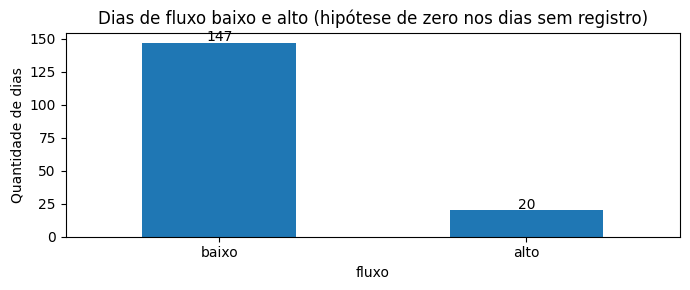

In [5]:
contagem = diario.fluxo.value_counts().reindex(['baixo','alto'])
ax = contagem.plot(kind='bar', title='Dias de fluxo baixo e alto (hipótese de zero nos dias sem registro)',
                   ylabel='Quantidade de dias', rot=0, figsize=(7,3))
for i, val in enumerate(contagem): ax.text(i, val+1, str(val), ha='center')
plt.tight_layout();plt.show()

## 6. Treinando e testando

Usei os **70% primeiros dias** para ensinar a árvore. Os **30% últimos dias** ficaram para testar. Não embaralhei as datas, porque o objetivo é prever dias seguintes usando o passado.

Usei uma Árvore de Decisão simples. A matriz de confusão mostra quantos dias o programa acertou e errou. Nela, as linhas são os valores reais e as colunas são as previsões.


In [6]:
modelo, treino, teste, previstos, metricas = treinar_avaliar(diario)
print('Treino:', metricas['n_treino'], 'dias | Teste:', metricas['n_teste'], 'dias')
print('Período do teste:', metricas['inicio_teste'], 'até', metricas['fim_teste'])
print('Acurácia do modelo: {:.1%}'.format(metricas['acuracia']))
print('Acurácia de prever sempre BAIXO: {:.1%}'.format(metricas['acuracia_sempre_baixo']))
print('Precisão de ALTO: {:.1%}'.format(metricas['precisao_alto']))
print('Sensibilidade/recall de ALTO: {:.1%}'.format(metricas['recall_alto']))
print('Matriz de confusão:', metricas['matriz'])
print(classification_report(teste['fluxo'], previstos, labels=['baixo','alto'], zero_division=0))

Treino: 116 dias | Teste: 51 dias
Período do teste: 2026-09-25 até 2026-11-14
Acurácia do modelo: 90.2%
Acurácia de prever sempre BAIXO: 92.2%
Precisão de ALTO: 42.9%
Sensibilidade/recall de ALTO: 75.0%
Matriz de confusão: [[43, 4], [1, 3]]
              precision    recall  f1-score   support

       baixo       0.98      0.91      0.95        47
        alto       0.43      0.75      0.55         4

    accuracy                           0.90        51
   macro avg       0.70      0.83      0.75        51
weighted avg       0.93      0.90      0.91        51



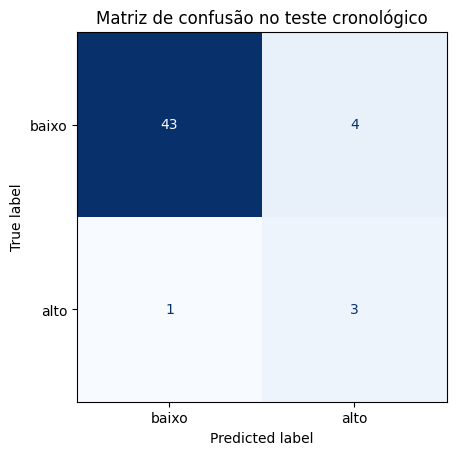

Condições aprendidas pela árvore:
|--- eh_sabado <= 0.50
|   |--- dia_semana <= 3.50
|   |   |--- class: baixo
|   |--- dia_semana >  3.50
|   |   |--- class: baixo
|--- eh_sabado >  0.50
|   |--- media_visitas_ultimos_7_dias <= 2.00
|   |   |--- class: alto
|   |--- media_visitas_ultimos_7_dias >  2.00
|   |   |--- class: baixo



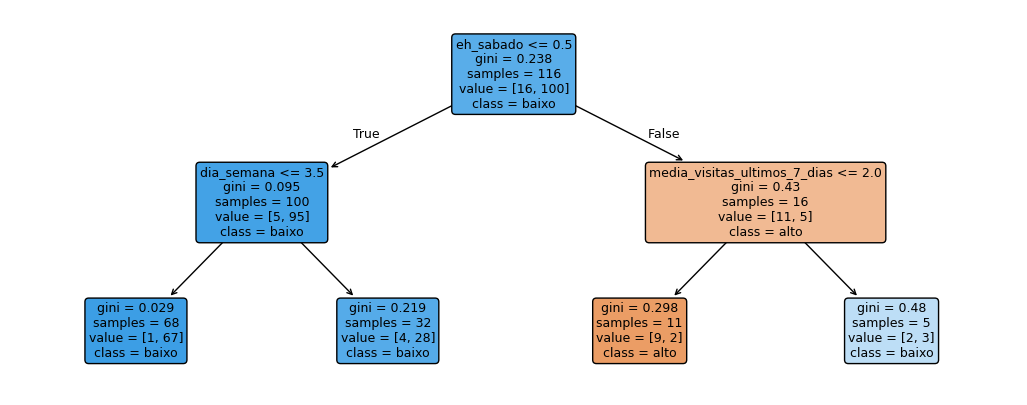

In [7]:
ConfusionMatrixDisplay(np.array(metricas['matriz']), display_labels=['baixo','alto']).plot(
    cmap='Blues',colorbar=False)
plt.title('Matriz de confusão no teste cronológico')
plt.show()
print('Condições aprendidas pela árvore:')
print(export_text(modelo, feature_names=ATRIBUTOS))
plt.figure(figsize=(13,5))
plot_tree(modelo, feature_names=ATRIBUTOS, class_names=list(modelo.classes_),
          filled=True, rounded=True, fontsize=9)
plt.show()

### 6.1. Entendendo o resultado

O programa acertou **46 de 51 dias (90,2%)**. Mesmo assim, ele fez quatro alertas de alto fluxo que estavam errados e deixou passar um dia alto. Como havia só quatro dias altos no teste, não posso dizer que o modelo está pronto para ser usado de verdade.


## 7. Sistema Especialista (SE)

A Árvore de Decisão fala se o dia será `alto` ou `baixo`. Depois, o Sistema Especialista verifica outra informação: se existe reforço disponível.

Criei quatro regras para mostrar o funcionamento:

- **R01:** SE fluxo alto E tem reforço, ENTÃO sugerir organizar reforço.
- **R02:** SE fluxo alto E não tem reforço, ENTÃO sugerir conferir a agenda e organizar a ordem.
- **R03:** SE fluxo baixo E tem reforço, ENTÃO deixar apoio de sobreaviso e confirmar futuras visitas.
- **R04:** SE fluxo baixo E não tem reforço, ENTÃO seguir atendimento normal e atualizar os registros.

Essas regras são ideias para o projeto. **Não são regras oficiais da empresa.**

O motor de inferência é a função que compara as informações com as regras e escolhe a que combina.


In [8]:
REGRAS = [{'id': 'R01', 'condicoes': {'fluxo': 'alto', 'reforco_disponivel': True}, 'acao': 'Organizar reforço para a recepção e distribuir atendimentos entre os profissionais disponíveis.', 'origem': 'Proposta inicial baseada na rotina informada do stand; precisa de validação da coordenação.'}, {'id': 'R02', 'condicoes': {'fluxo': 'alto', 'reforco_disponivel': False}, 'acao': 'Conferir a agenda, organizar a ordem de atendimento e comunicar a equipe sobre possível concentração de visitas.', 'origem': 'Proposta inicial baseada na rotina informada do stand; precisa de validação da coordenação.'}, {'id': 'R03', 'condicoes': {'fluxo': 'baixo', 'reforco_disponivel': True}, 'acao': 'Manter uma pessoa de apoio de sobreaviso e aproveitar intervalos para confirmar visitas futuras.', 'origem': 'Proposta inicial baseada na rotina informada do stand; precisa de validação da coordenação.'}, {'id': 'R04', 'condicoes': {'fluxo': 'baixo', 'reforco_disponivel': False}, 'acao': 'Manter o atendimento normal e atualizar os registros e as confirmações da agenda.', 'origem': 'Proposta inicial baseada na rotina informada do stand; precisa de validação da coordenação.'}]

for r in REGRAS:
    print(r["id"], "|", r["condicoes"], "=>", r["acao"])

R01 | {'fluxo': 'alto', 'reforco_disponivel': True} => Organizar reforço para a recepção e distribuir atendimentos entre os profissionais disponíveis.
R02 | {'fluxo': 'alto', 'reforco_disponivel': False} => Conferir a agenda, organizar a ordem de atendimento e comunicar a equipe sobre possível concentração de visitas.
R03 | {'fluxo': 'baixo', 'reforco_disponivel': True} => Manter uma pessoa de apoio de sobreaviso e aproveitar intervalos para confirmar visitas futuras.
R04 | {'fluxo': 'baixo', 'reforco_disponivel': False} => Manter o atendimento normal e atualizar os registros e as confirmações da agenda.


## 8. Juntando previsão e regra

A função `consultar` primeiro pede a previsão à Árvore de Decisão. Depois, ela envia o resultado e a informação sobre reforço para o Sistema Especialista. O programa mostra qual regra foi usada e a recomendação.


In [9]:
dia = diario.loc[diario.data == pd.Timestamp('2026-09-26')].iloc[0]
resposta = consultar(modelo, dia[ATRIBUTOS].to_dict(), True, REGRAS)
for chave, valor in resposta.items(): print(chave, ':', valor)

fluxo_previsto : alto
regra : R01
recomendacao : Organizar reforço para a recepção e distribuir atendimentos entre os profissionais disponíveis.
explicacao : Modelo previu alto; reforço disponível = True.
aviso : Sugestão didática: a previsão pode errar; confirme os dados e revise com a equipe.


## 9. Três dias que não foram usados no treinamento

Vou testar três dias que ficaram na parte de teste:

- **26/09/2026:** 7 visitas, fluxo alto.
- **03/10/2026:** 3 visitas, fluxo baixo.
- **21/10/2026:** 2 visitas, fluxo baixo.

A informação sobre ter reforço disponível foi simulada, porque não está no relatório.


In [10]:
CASOS = [('2026-09-26', True), ('2026-10-03', False), ('2026-10-21', True)]
for i, (data_txt, reforco) in enumerate(CASOS,1):
    linha = diario.loc[diario.data == pd.Timestamp(data_txt)].iloc[0]
    assert linha.name in teste.index
    resultado = consultar(modelo, linha[ATRIBUTOS].to_dict(), reforco, REGRAS)
    print(f'CASO {i} | data={data_txt} | visitas reais={linha.total_visitas} | rótulo={linha.fluxo}')
    print('  Previsão:', resultado['fluxo_previsto'], '| Regra:', resultado['regra'],
          '| Acerto:', resultado['fluxo_previsto'] == linha.fluxo)
    print('  Recomendação:', resultado['recomendacao'])
    print('  Explicação:', resultado['explicacao'],'\n')

CASO 1 | data=2026-09-26 | visitas reais=7 | rótulo=alto
  Previsão: alto | Regra: R01 | Acerto: True
  Recomendação: Organizar reforço para a recepção e distribuir atendimentos entre os profissionais disponíveis.
  Explicação: Modelo previu alto; reforço disponível = True. 

CASO 2 | data=2026-10-03 | visitas reais=3 | rótulo=baixo
  Previsão: baixo | Regra: R04 | Acerto: True
  Recomendação: Manter o atendimento normal e atualizar os registros e as confirmações da agenda.
  Explicação: Modelo previu baixo; reforço disponível = False. 

CASO 3 | data=2026-10-21 | visitas reais=2 | rótulo=baixo
  Previsão: baixo | Regra: R03 | Acerto: True
  Recomendação: Manter uma pessoa de apoio de sobreaviso e aproveitar intervalos para confirmar visitas futuras.
  Explicação: Modelo previu baixo; reforço disponível = True. 



### 9.1. O que muda quando existe reforço?

Se eu mudar somente a resposta sobre reforço, a previsão alto/baixo continua igual. O que muda é a regra aplicada e a sugestão. Isso mostra a diferença entre a parte que aprende e a parte que usa regras humanas.


In [11]:
mesmo_dia = diario.loc[diario.data == pd.Timestamp('2026-09-26')].iloc[0]
for reforco in (True, False):
    out = consultar(modelo, mesmo_dia[ATRIBUTOS].to_dict(), reforco, REGRAS)
    print('Reforço:', reforco, '| previsão:', out['fluxo_previsto'],
          '| regra:', out['regra'], '| ação:', out['recomendacao'])

Reforço: True | previsão: alto | regra: R01 | ação: Organizar reforço para a recepção e distribuir atendimentos entre os profissionais disponíveis.
Reforço: False | previsão: alto | regra: R02 | ação: Conferir a agenda, organizar a ordem de atendimento e comunicar a equipe sobre possível concentração de visitas.


## 10. Exemplo de consulta para o dia seguinte

Para este exemplo, o programa treina outro modelo com todo o histórico e faz uma consulta para o dia depois do último registro. Como o arquivo termina em 14/11/2026, o exemplo é para **15/11/2026**, uma data que já passou. Esta não é uma previsão atual.


In [12]:
modelo_demonstra = DecisionTreeClassifier(max_depth=2,min_samples_leaf=4,random_state=42)
modelo_demonstra.fit(diario[ATRIBUTOS], diario['fluxo'])
data_futura, entrada_futura = entrada_proximo_dia(diario)
print('Dia de demonstração (histórico):', data_futura.date())
print('Entrada:', entrada_futura)
print('Resultado:', consultar(modelo_demonstra,entrada_futura,True,REGRAS))

Dia de demonstração (histórico): 2026-11-15
Entrada: {'dia_semana': 6, 'eh_sabado': 0, 'mes': 11, 'visitas_dia_anterior': 1, 'media_visitas_ultimos_7_dias': 0.5714285714285714, 'agendadas_ultimos_7_dias': 3}
Resultado: {'fluxo_previsto': 'baixo', 'regra': 'R03', 'recomendacao': 'Manter uma pessoa de apoio de sobreaviso e aproveitar intervalos para confirmar visitas futuras.', 'explicacao': 'Modelo previu baixo; reforço disponível = True.', 'aviso': 'Sugestão didática: a previsão pode errar; confirme os dados e revise com a equipe.'}


## 11. O que aprendi e os cuidados com o projeto

1. Existem **63 dias sem registros** que tratei como zero só para o exercício. Preciso conferir se realmente foram dias sem visitas.
2. São **20 dias altos em 167 dias**. O programa tem poucos exemplos de alto fluxo para aprender.
3. O movimento pode mudar em feriados, campanhas e outros meses.
4. O relatório não tem os agendamentos confirmados no dia anterior, que seriam úteis para prever.
5. O limite de **4 visitas** foi escolhido por mim com base na rotina do stand. Ele não é uma regra universal.
6. Não coloquei nomes de clientes ou corretores nos dados usados no notebook.
7. O sistema apenas sugere ações. A decisão final deve ser tomada pela equipe.
8. Usei o ChatGPT (GPT-6) como apoio para organizar o texto, o código e os testes. Vou conferir o material antes da entrega.

**Perguntas finais da aula:** quem aprende com os dados é a função `modelo.fit`. Quem aplica as regras é a função `aplicar_regras`. Não coloquei a disponibilidade de reforço nos dados X porque ela é uma informação usada depois da previsão. Mudar essa informação altera a sugestão, mas não a previsão. Mesmo 100% de acerto em poucos casos não é suficiente para afirmar que um programa funciona bem na vida real.

### Materiais usados
- Aula 12 — Sistemas Especialistas, Profa. Kadidja Valéria, UDF.
- Aula 13 — Aprendizado de Máquina, Profa. Kadidja Valéria, UDF.
- Exemplo de Sistema Especialista para Diagnóstico de Computador (DiagPC).
- Exemplo `Atividade_Aprendizado_Maquina.ipynb`.
- Roteiro Ética e Impactos da Inteligência Artificial (UDF, 2026).
- Relatório de atendimentos do ROYAL BOTANIC, gerado em 15/11/2026.
